# Automotive Fuel Efficiency Analysis & Prediction
**Author:** Pratik Pawar  
**Project type:** Exploratory Data Analysis + Predictive Analytics  
**Domain:** Automotive

## Business objective
Explore which vehicle characteristics are associated with fuel efficiency (miles per gallon / MPG), compare average MPG across vehicle origins, and build a baseline regression model to estimate MPG from vehicle specifications.

> This is a historical dataset of cars from the 1970s and early 1980s. Findings describe patterns in this dataset; they should not be interpreted as causal effects or as representative of today's vehicles.

## Project workflow
1. Load and inspect the data
2. Clean missing values and check data quality
3. Explore distributions, relationships and group-level patterns
4. Prepare a reproducible train/test split
5. Build a preprocessing + Linear Regression pipeline
6. Evaluate against a simple baseline
7. Summarize findings, limitations and next steps



## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

The Auto MPG dataset contains vehicle fuel-efficiency observations and vehicle attributes. The target variable is `mpg`.

If you have downloaded a CSV, set `LOCAL_CSV_PATH` to its location. Otherwise, the notebook tries Seaborn's dataset loader and then the UCI source.

In [2]:
LOCAL_CSV_PATH = None  # Example: "auto-mpg.csv"

if LOCAL_CSV_PATH:
    df = pd.read_csv(LOCAL_CSV_PATH)
else:
    try:
        df = sns.load_dataset("mpg")
    except Exception:
        # UCI raw file: whitespace-separated data; '?' represents missing horsepower.
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
        columns = [
            "mpg", "cylinders", "displacement", "horsepower", "weight",
            "acceleration", "model_year", "origin", "name"
        ]
        df = pd.read_csv(
            url, sep=r"\s+", names=columns, na_values="?",
            skipinitialspace=True
        )

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 3. Initial data inspection

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB

Missing values by column:


,missing_values
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0



Duplicate rows: 0


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mpg,398.0,NaN,NaN,NaN,23.514573,7.815984,9.0,17.5,23.0,29.0,46.6
cylinders,398.0,NaN,NaN,NaN,5.454774,1.701004,3.0,4.0,4.0,8.0,8.0
displacement,398.0,NaN,NaN,NaN,193.425879,104.269838,68.0,104.25,148.5,262.0,455.0
horsepower,392.0,NaN,NaN,NaN,104.469388,38.49116,46.0,75.0,93.5,126.0,230.0
weight,398.0,NaN,NaN,NaN,2970.424623,846.841774,1613.0,2223.75,2803.5,3608.0,5140.0
acceleration,398.0,NaN,NaN,NaN,15.56809,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,NaN,NaN,NaN,76.01005,3.697627,70.0,73.0,76.0,79.0,82.0
origin,398,3,usa,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,398,305,ford pinto,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data cleaning

Standardize column names, convert the `origin` codes used in the UCI version into readable labels, and inspect missing values. Missing numeric values are imputed inside the modelling pipeline so the imputer learns only from the training data.

In [5]:
df.columns = [str(col).strip().lower().replace(" ", "_") for col in df.columns]

# Convert UCI origin codes (1, 2, 3) into readable categories.
if "origin" in df.columns:
    origin_map = {1: "usa", 2: "europe", 3: "japan"}
    df["origin"] = df["origin"].replace(origin_map).astype("object")

# Ensure numeric fields are numeric when the data comes from a local CSV.
numeric_candidates = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove exact duplicate rows, if any.
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

print("Duplicate rows removed:", duplicate_count)
print("Missing values after standardization:")
display(df.isna().sum().to_frame("missing_values"))

Duplicate rows removed: 0
Missing values after standardization:


,missing_values
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


### Data quality decisions
- `mpg` is the target. Rows without a target value cannot be used for supervised training and are excluded.
- Missing predictor values are retained and imputed with the median within the training pipeline.
- The `name` field is descriptive text and is not used in this baseline model.

In [6]:
df = df.dropna(subset=["mpg"]).copy()

required_columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

print("Analysis-ready shape:", df.shape)

Analysis-ready shape: (398, 9)


## 5. Exploratory Data Analysis (EDA)

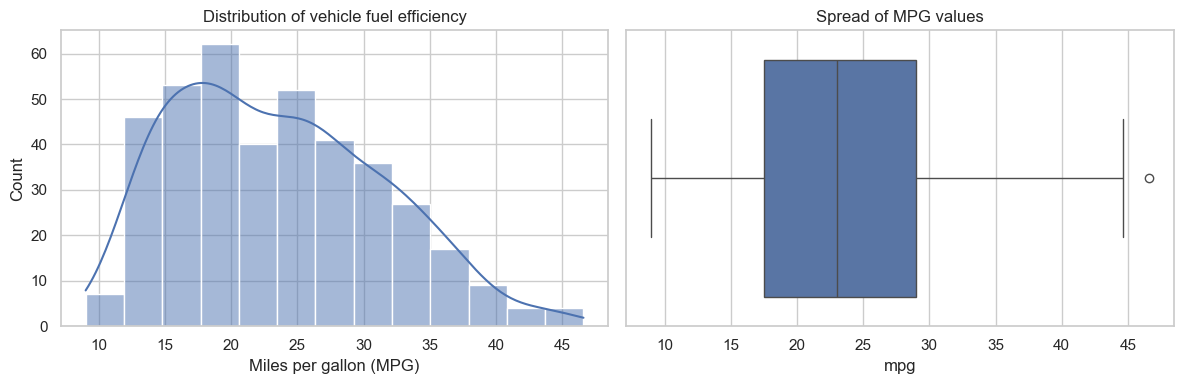

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="mpg", kde=True, ax=axes[0])
axes[0].set_title("Distribution of vehicle fuel efficiency")
axes[0].set_xlabel("Miles per gallon (MPG)")

sns.boxplot(data=df, x="mpg", ax=axes[1])
axes[1].set_title("Spread of MPG values")
plt.tight_layout()
plt.show()

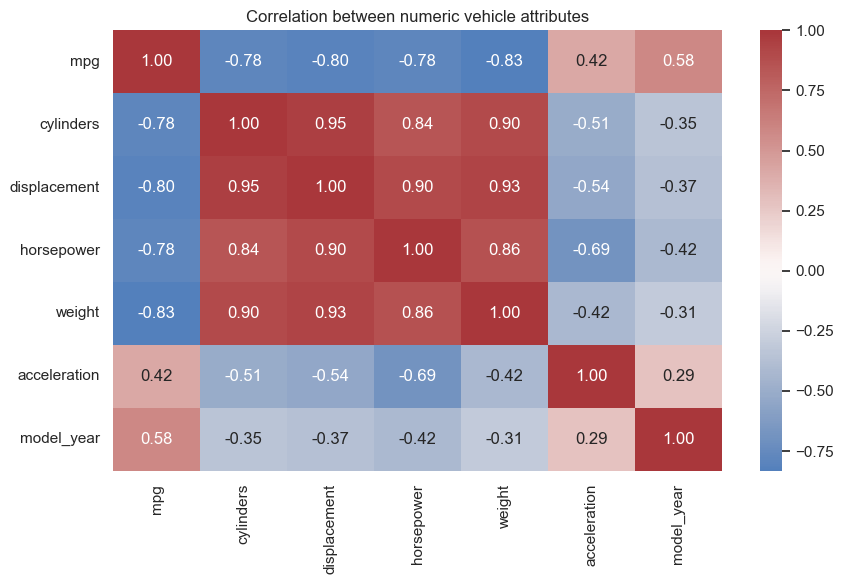

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(9, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation between numeric vehicle attributes")
plt.tight_layout()
plt.show()

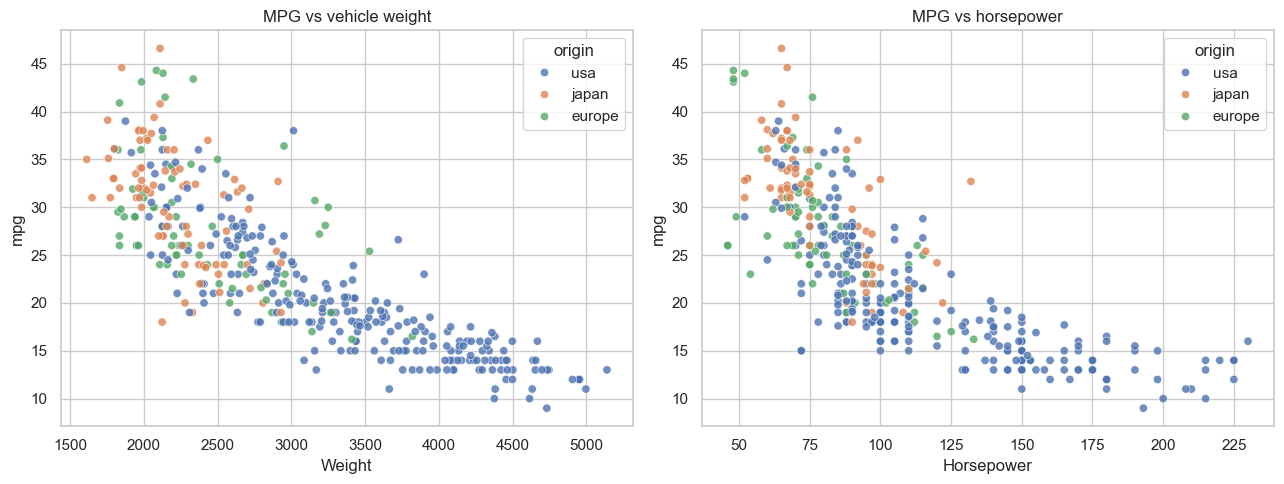

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df, x="weight", y="mpg", hue="origin", alpha=0.8, ax=axes[0])
axes[0].set_title("MPG vs vehicle weight")
axes[0].set_xlabel("Weight")

sns.scatterplot(data=df, x="horsepower", y="mpg", hue="origin", alpha=0.8, ax=axes[1])
axes[1].set_title("MPG vs horsepower")
axes[1].set_xlabel("Horsepower")

plt.tight_layout()
plt.show()

,origin,vehicle_count,average_mpg,median_mpg
1,japan,79,30.45,31.6
0,europe,70,27.89,26.5
2,usa,249,20.08,18.5


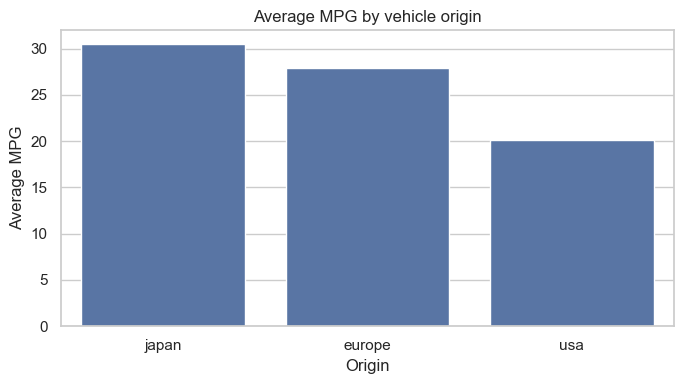

In [10]:
origin_summary = (
    df.groupby("origin", as_index=False)
      .agg(vehicle_count=("mpg", "size"), average_mpg=("mpg", "mean"), median_mpg=("mpg", "median"))
      .sort_values("average_mpg", ascending=False)
)
display(origin_summary.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(data=origin_summary, x="origin", y="average_mpg")
plt.title("Average MPG by vehicle origin")
plt.xlabel("Origin")
plt.ylabel("Average MPG")
plt.tight_layout()
plt.show()

### EDA observations

Use the charts and summary table above to validate these questions:
- Is MPG distributed symmetrically, or is it skewed?
- How does MPG vary with vehicle weight and horsepower?
- Do average MPG values differ across vehicle origins?
- Which numeric variables show the strongest association with MPG?

**Interpretation caution:** correlation and group averages describe association, not proof that one vehicle attribute causes a change in MPG.

## 6. Prepare features and split the data

In [11]:
target = "mpg"
numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_features = ["origin"]
features = numeric_features + categorical_features

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 318
Testing rows: 80


## 7. Build a reproducible modelling pipeline

The pipeline performs median imputation for numeric predictors, most-frequent imputation and one-hot encoding for the categorical `origin` feature, then fits Linear Regression.

Using a pipeline helps prevent preprocessing leakage: imputation and category encoding are fitted using the training data only.

In [12]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 8. Evaluate model performance

In [13]:
def regression_metrics(y_true, y_hat):
    return {
        "MAE (mpg)": mean_absolute_error(y_true, y_hat),
        "RMSE (mpg)": np.sqrt(mean_squared_error(y_true, y_hat)),
        "R-squared": r2_score(y_true, y_hat)
    }

# Baseline: predict the mean MPG from the training set for every test observation.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[numeric_features], y_train)
baseline_pred = baseline.predict(X_test[numeric_features])

results = pd.DataFrame({
    "Baseline (mean predictor)": regression_metrics(y_test, baseline_pred),
    "Linear Regression pipeline": regression_metrics(y_test, y_pred)
}).T

display(results.round(3))

,MAE (mpg),RMSE (mpg),R-squared
Baseline (mean predictor),5.955,7.347,-0.004
Linear Regression pipeline,2.288,2.888,0.845


**Metric guide**
- **MAE:** average absolute prediction error, in MPG. Lower is better.
- **RMSE:** penalizes larger errors more heavily, in MPG. Lower is better.
- **R²:** proportion of test-set target variance explained by the model. Higher is generally better; it can be negative on poor predictions.



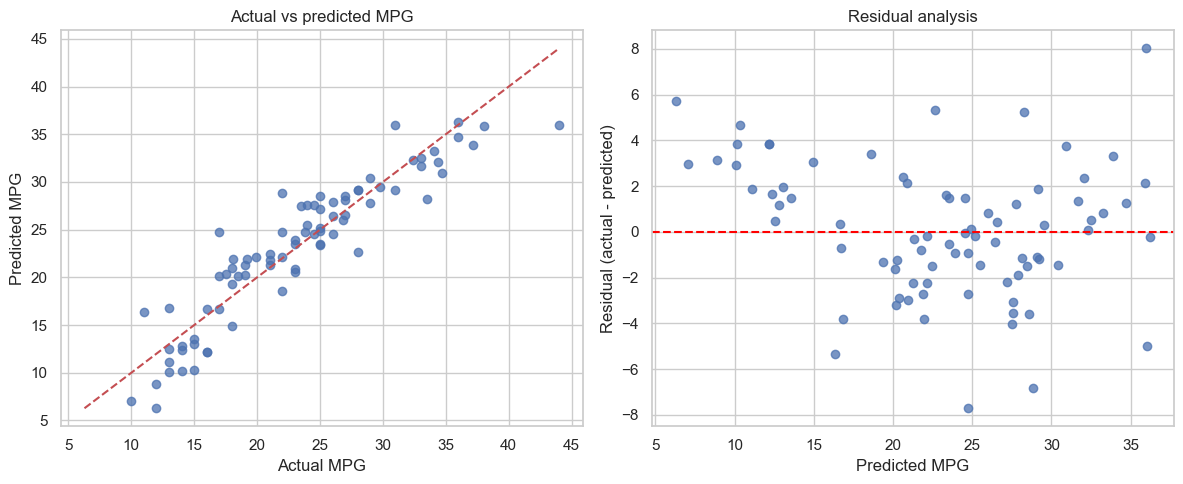

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.75)
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
axes[0].plot([line_min, line_max], [line_min, line_max], "r--")
axes[0].set_xlabel("Actual MPG")
axes[0].set_ylabel("Predicted MPG")
axes[0].set_title("Actual vs predicted MPG")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.75)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted MPG")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residual analysis")

plt.tight_layout()
plt.show()

## 9. Business interpretation

Use the EDA charts, origin summary and test metrics to write a short evidence-based interpretation. A useful structure is:

1. **Pattern:** What relationship or group difference did you observe?
2. **Evidence:** Which chart, summary statistic or model metric supports it?
3. **Business relevance:** Why could this matter to a vehicle manufacturer, fleet operator or buyer?
4. **Caveat:** What does this dataset not allow you to conclude?


In [15]:
# Generate a compact, data-backed summary from the results above.
best_origin = origin_summary.iloc[0]
lowest_origin = origin_summary.iloc[-1]
model_metrics = regression_metrics(y_test, y_pred)

print(f"Highest average MPG origin in this sample: {best_origin['origin']} "
      f"({best_origin['average_mpg']:.2f} MPG).")
print(f"Lowest average MPG origin in this sample: {lowest_origin['origin']} "
      f"({lowest_origin['average_mpg']:.2f} MPG).")
print(f"Test MAE: {model_metrics['MAE (mpg)']:.2f} MPG")
print(f"Test RMSE: {model_metrics['RMSE (mpg)']:.2f} MPG")
print(f"Test R-squared: {model_metrics['R-squared']:.3f}")

Highest average MPG origin in this sample: japan (30.45 MPG).
Lowest average MPG origin in this sample: usa (20.08 MPG).
Test MAE: 2.29 MPG
Test RMSE: 2.89 MPG
Test R-squared: 0.845


## 10. Conclusion, limitations and next steps

### Conclusion
This project combines data cleaning, exploratory analysis, group comparisons and a baseline regression model to investigate vehicle fuel efficiency in the Auto MPG dataset.

### Limitations
- The dataset is historical and contains a relatively small number of observations.
- The model is a baseline Linear Regression model; more complex relationships may not be captured.
- The train/test result depends on the selected random split.
- Observational associations do not establish causation.
- Results should not be generalized to modern vehicles without new data and validation.


### Tools and technologies
Python • Pandas • NumPy • Matplotlib • Seaborn • Scikit-learn • Jupyter Notebook